# 数据类型

In [1]:
from helper.python import print_subclasses
from helper.jupyter import row
import numpy as np
import polars as pl

Polars 提供了多种数据类型，用来高效地保存和计算不同的数据。本章依次介绍这些类型，说明各自的特性与用途。

选择哪种类型，会同时影响内存占用和可用的运算。例如把日期存成字符串，排序就会按字典序进行，减法也会直接报错；把金额存成 `Float64`，累加次数一多就会出现小数误差。因此，先弄清有哪些类型、各自适合什么场景，再编写转换。

## 数据类型的继承树

Polars 的数据类型较多，彼此之间有明确的继承关系。下面先看继承树的结构，再逐个说明各类型。这棵树既展示类型如何组织，也说明哪些类型之间可以互相转换。`NumericType`、`TemporalType` 这些主要类型还分成更具体的子类，各自针对一类数据处理做了优化，`NestedType` 则负责列表、结构体这类嵌套结构。

In [2]:
print_subclasses(pl.DataType)

└──DataType
   ├──NumericType
   │  ├──IntegerType
   │  │  ├──SignedIntegerType
   │  │  │  ├──Int8
   │  │  │  ├──Int16
   │  │  │  ├──Int32
   │  │  │  ├──Int64
   │  │  │  └──Int128
   │  │  └──UnsignedIntegerType
   │  │     ├──UInt8
   │  │     ├──UInt16
   │  │     ├──UInt32
   │  │     ├──UInt64
   │  │     └──UInt128
   │  ├──FloatType
   │  │  ├──Float16
   │  │  ├──Float32
   │  │  └──Float64
   │  └──Decimal
   ├──TemporalType
   │  ├──Date
   │  ├──Time
   │  ├──Datetime
   │  └──Duration
   ├──NestedType
   │  ├──List
   │  ├──Map
   │  ├──Array
   │  └──Struct
   ├──ObjectType
   │  └──Object
   ├──Boolean
   ├──String
   ├──Binary
   ├──Categorical
   ├──Enum
   ├──Null
   ├──Unknown
   └──BaseExtension
      └──Extension


**数值型**

- **NumericType**：数值型的基类，处理整数型、浮点型等数值数据。
  - **IntegerType**：整数数据的基类。
    - **SignedIntegerType**：有符号整数，如 `Int8`、`Int16`、`Int32`、`Int64`。
    - **UnsignedIntegerType**：无符号整数，如 `UInt8`、`UInt16`、`UInt32`、`UInt64`。
  - **FloatType**：浮点数据的基类，如 `Float32`、`Float64`。
  - **Decimal**：定点小数，用于高精度数值计算。

**时序型**

- **TemporalType**：与时间相关的数据类型的基类。
  - **Date**：日期，例如 `2024-07-18`。
  - **Time**：时刻，例如 `12:34:56`。
  - **Datetime**：日期时间，例如 `2024-07-18 12:34:56`。
  - **Duration**：时间长度，例如 5 分钟、2 小时。

**嵌套型**

- **NestedType**：带嵌套结构的数据类型的基类。
  - **List**：元素列表，列表内的元素必须是同一数据类型。
  - **Array**：定长数组。
  - **Struct**：结构体，可以带多个数据类型不同的字段。

**其他类型**

- **Boolean**：真值，取 `True` 或 `False`。
- **String**：字符串数据。
- **Binary**：二进制数据。
- **Categorical**：分类数据，按类别值高效管理。
- **Enum**：枚举型数据。
- **Object**：任意 Python 对象，用于存放不匹配特定类型的数据。
- **Null**：NULL 值，用于表示缺失值。
- **Unknown**：未知的数据类型。

## 数据类型转换

### Cast

Polars 提供了多种类型转换函数，最常用的两个是 `cast()` 和 `shrink_dtype()`：前者改变类型，后者在保持值不变的前提下把类型收缩到满足需要的最小尺寸。下面分别说明。

In [3]:
df = pl.DataFrame(
    {
        "a": [3, 3, 3, 4],
        "b": [4, 12, 6, 7],
        "g": ['B', 'A', 'A', 'C']
    }
)
df

a,b,g
i64,i64,str
3,4,"""B"""
3,12,"""A"""
3,6,"""A"""
4,7,"""C"""


`cast()` 把列转换为指定的数据类型，用于改变数据的表示形式，例如把整数列转成浮点列，或把字符串列转成日期型。

转换失败时默认直接报错，这比悄无声息地变成 NULL 更安全。数据里确实有异常值时，可以改用 `strict=False`，让这些值变成 NULL，后续如何处理由调用方决定。

In [4]:
df.with_columns(
    pl.col.a.cast(pl.UInt8),
    pl.col.b.cast(pl.String)
)

a,b,g
u8,str,str
3,"""4""","""B"""
3,"""12""","""A"""
3,"""6""","""A"""
4,"""7""","""C"""


`shrink_dtype()` 按值的范围把数据类型收缩到所需的最小尺寸。例如 `Int64` 的列实际只需要 `Int8` 时，内存占用可以降到八分之一。

这对内存和缓存都很友好，代价是多一次全列扫描。Polars 2.0 中它不能再从表达式(`Expr`)上调用，而改成了 `Series` 的方法，所以要先在列上取出 `Series`，再收缩类型。

In [5]:
df2 = pl.DataFrame({name: df[name].shrink_dtype() for name in df.columns})

print(df.dtypes)
print(df2.dtypes)

[Int64, Int64, String]
[Int8, Int8, String]


在 8 位和 16 位整数上，有符号型与无符号型之间的转换需要把 `cast()` 的 `wrap_numerical` 参数设为 `True`。默认情况下，Polars 会检查值是否落在目标类型的范围内；设为 `True` 后，超出范围的值按补码回绕，而不是报错。

这个参数目前只支持 8 位和 16 位整数：`Int8` 与 `UInt8`、`Int16` 与 `UInt16` 之间位宽相同，回绕后的结果就是按另一种符号解释同一串位。下面的代码先把 `Int16` 负值转成 `UInt16`，再把 `UInt16` 大值转回 `Int16`，以观察回绕效果。

In [6]:
df = pl.DataFrame(
    [
        pl.Series("A", [1, 2, -1, -2], dtype=pl.Int16),
        pl.Series("B", [1, 2, 0xffff, 0xfffe], dtype=pl.UInt16)
    ]
)

df.select(
    pl.col('A').cast(pl.UInt16, wrap_numerical=True),
    pl.col('B').cast(pl.Int16, wrap_numerical=True),
)

A,B
u16,i16
1,1
2,2
65535,-1
65534,-2


### 重新解释数据类型

`cast()` 会改变数据的数值，而有时候要保留原来的字节表示、只按另一种类型去读，类似 NumPy 的 `.view()`，这时用 `reinterpret()`。

两者的区别在于是否改变数值：`cast(pl.Int64)` 从 `3.0` 得到 `3`，`reinterpret` 则按位重新解释，结果可能完全不同。它的用途就是“同一串字节，换一种读法”。

In [7]:
df_wrong = pl.DataFrame({"nums": [4837362400224322580, None, 4837362400224322584]}, schema={"nums": pl.UInt64})
df_fixed = df_wrong.select(pl.col("nums").reinterpret(dtype=pl.Float64))
row(df_wrong, df_fixed)


nums
u64
4837362400224322580
null
4837362400224322584
nums
f64
2.5000e15
null
2.5000e15


`reinterpret()` 的 `signed` 参数用于在有符号整数与无符号整数之间重新解释：`signed=False` 按无符号整数读，`signed=True` 按有符号整数读。

另外，`reinterpret(dtype=...)` 也能在整数与浮点数之间转换，但源类型与目标类型的字节大小必须相同，例如把 `Int32` 重新解释成 `Int64` 就会因为大小不同而报错。下面的代码演示如何使用 `signed` 参数在有符号整数与无符号整数之间转换。

In [8]:
df = pl.DataFrame(
    [
        pl.Series("A", [1, 2, -1, -2], dtype=pl.Int32),
        pl.Series("B", [1, 2, 0xffffffff, 0xfffffffe], dtype=pl.UInt32)
    ]
)

df.with_columns(
    pl.col('A').reinterpret(signed=False),
    pl.col('B').reinterpret(signed=True)
)

A,B
u32,i32
1,1
2,2
4294967295,-1
4294967294,-2


要把二进制数据转换为字节数相同的数据类型，可以用 `bin.reinterpret()`。`dtype` 参数指定转换后的类型，`endianness` 参数指定字节序，取 `"big"` 或 `"little"`。下面的例子把二进制数据转换为 4 字节无符号整数 `UInt32`，并按大端(big-endian)解释。

In [9]:
df = pl.DataFrame({
    'binary_column': [b'\x00\x00\x00\x01', b'\x00\x00\x00\x02', b'\x00\x00\x00\x03', b'\x00\x00@A']
})

df.select(pl.col('binary_column').bin.reinterpret(dtype=pl.UInt32, endianness="big"))

binary_column
u32
1
2
3
16449


下面看一个具体例子：《Quake III Arena》C 源代码中的快速平方根倒数(Fast inverse square root)。

这段代码用一个魔数 `0x5f3759df`，把浮点数按整数重新解释，再通过一次整数运算和一次牛顿迭代快速算出平方根的倒数。它当年是为了在没有浮点除法的硬件上计算光照，如今成了“类型重解释”最著名的例子。

In [10]:
import numpy as np
number = np.linspace(0.1, 10, 100)
y = number.astype(np.float32)  #❶
x2 = y * 0.5
i = y.view(np.int32)  #❷
i[:] = 0x5F3759DF - (i >> 1)  #❸
y = y * (1.5 - x2 * y * y)  #❹
np.max(np.abs(1 / np.sqrt(number) - y))  #❺

np.float64(0.005045614041059743)

用 Polars 的 `reinterpret()` 可以实现同样的计算。关键在于分清两个动作：`cast()` 转换数值，`reinterpret()` 保留字节表示、只改变类型。下面的实现先把整数位移，再用 `reinterpret()` 读回浮点，最后用一次牛顿迭代提高精度。

In [11]:
import polars as pl
import numpy as np

# 用 Polars 的 reinterpret 实现 Q_rsqrt
number = np.linspace(0.1, 10, 100)
df = pl.DataFrame({"number": number})

result = (
    df.with_columns(pl.col("number").cast(pl.Float32).alias("y"))  #❶
    .with_columns((pl.col("y") * 0.5).alias("x2"))
    .with_columns(pl.col("y").reinterpret(dtype=pl.Int32).alias("i"))  #❷
    .with_columns(
        (0x5F3759DF - pl.col("i") // 2)  #❸
        .reinterpret(dtype=pl.Float32)
        .alias("y_approx")
    )
    .with_columns(
        (pl.col("y_approx") * (1.5 - pl.col("x2") * pl.col("y_approx") * pl.col("y_approx")))
        .alias("y_result")  #❹
    )
)

y_result = result["y_result"].to_numpy()
max_err = np.max(np.abs(1.0 / np.sqrt(number) - y_result))
print(f"最大误差: {max_err}")  #❺
result.head(5)  # 显示部分结果


最大误差: 0.005045614041059743


number,y,x2,i,y_approx,y_result
f64,f32,f32,i32,f32,f32
0.1,0.1,0.05,1036831949,3.26486,3.157232
0.2,0.2,0.1,1045220557,2.26486,2.23551
0.3,0.3,0.15,1050253722,1.83243,1.825705
0.4,0.4,0.2,1053609165,1.63243,1.578616
0.5,0.5,0.25,1056964608,1.43243,1.41386


把误差的分布画出来。`number` 较小时绝对误差较大，但此时函数值本身也大，所以相对误差的变化并不明显。

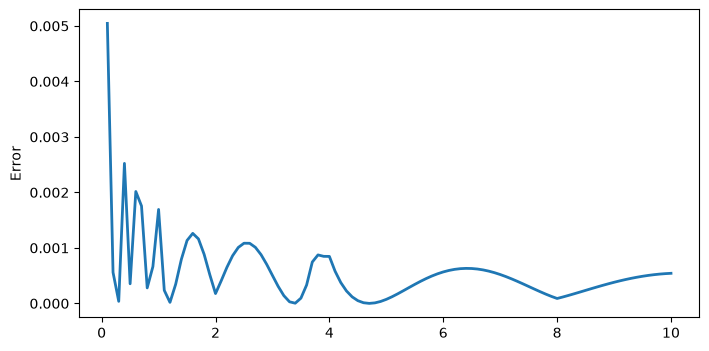

In [12]:
import matplotlib.pyplot as plt
y_result = result["y_result"].to_numpy()

plt.figure(figsize=(8, 4))
plt.plot(number, 1 / np.sqrt(number) - y_result, lw=2)
plt.ylabel("Error");

## 字符串

Polars 处理字符串的能力同样很强，相关的表达式函数都在 `.str` 命名空间下。

和 Python 的字符串方法相比，这些函数是向量化的：一次作用于整列，不必写循环，也不会为每个值新建对象。

### 字符串长度

* `str.len_chars()`：统计字符串的字符数，也就是字符串中实际有几个字符。多字节字符(像日语里的假名)同样按 1 个字符计。
* `str.len_bytes()`：统计字符串的字节数，也就是各字符编码后占用字节数的总和。多字节字符按多个字节计。

In [13]:
df = pl.DataFrame({
    "lib": ["pandas", "numpy", "polars", "図形"],
    "ver": ["2.0", "1.1.4", "1.2.1", "4.0"]
})

df.select(
    "lib",
    len_char=pl.col("lib").str.len_chars(),
    len_byte=pl.col("lib").str.len_bytes()
)

lib,len_char,len_byte
str,u32,u32
"""pandas""",6,6
"""numpy""",5,5
"""polars""",6,6
"""図形""",2,6


### 字符串的部分匹配检索

用 `str.contains()`、`str.starts_with()`、`str.ends_with()` 等函数，可以检查是否包含特定子串、是否以指定字符串开头或结尾。

这些检查默认按字面量匹配，只有传入 `literal=False` 才按正则解释。如果把 `literal` 设错，就会得到意料之外的匹配结果。

In [14]:
df.filter(pl.col.lib.str.starts_with("p"))

lib,ver
str,str
"""pandas""","""2.0"""
"""polars""","""1.2.1"""


In [15]:
df.filter(pl.col.ver.str.ends_with("0"))

lib,ver
str,str
"""pandas""","""2.0"""
"""図形""","""4.0"""


In [16]:
df.filter(pl.col.lib.str.contains('p'))

lib,ver
str,str
"""pandas""","""2.0"""
"""numpy""","""1.1.4"""
"""polars""","""1.2.1"""


`.str.contains()` 也支持正则表达式。下面的代码取出形如“三个数字、两个点”的版本号所在的行。

In [17]:
df.filter(pl.col.ver.str.contains("^\d+\.\d+\.\d+$"))

<>:1: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
<>:1: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
C:\Users\ruoyu\AppData\Local\Temp\ipykernel_2356\1031424121.py:1: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
  df.filter(pl.col.ver.str.contains("^\d+\.\d+\.\d+$"))


lib,ver
str,str
"""numpy""","""1.1.4"""
"""polars""","""1.2.1"""


`.str.contains_any()` 判断是否包含给定字符串或模式列表中的任意一个，用于一次检查多个关键词，比如从文本里筛出提到若干地名的行。

In [18]:
df2 = pl.DataFrame({
    "text": ["hello world", "data process library", "data science", "machine learning", "plot library"]
})

df2.filter(
    pl.col("text").str.contains_any(["science", "machine"])
)

text
str
"""data science"""
"""machine learning"""


`.str.contains_any()` 的参数也可以传表达式。直接传一列时，Polars 会把整列当成一个值，而不是逐行使用；因此要先 `implode()` 把整列压成一个列表，再传给模式列表参数。

这里容易出错：`implode()` 的作用正是把整列压成一个列表值，恰好对上“模式列表”这个参数。下面的代码先统计 `text` 列中出现频率最高的两个词，再用它们筛选包含这两个词的行。

In [19]:
expr = (
    pl.col.text.str.split(" ").explode().value_counts(sort=True).head(2).struct.field("text")
)
# 用 implode() 变成“值的列表”后再传给 contains_any
row(df2.select(expr), df2.filter(pl.col("text").str.contains_any(expr.implode())))

text
str
"""data"""
"""library"""
text
str
"""data process library"""
"""data science"""
"""plot library"""


### 字符串替换

`.str.replace()`、`.str.replace_all()` 用于替换特定的子串。

- `str.replace()`：只替换最先找到的前 `n` 个匹配，默认替换 1 个。
- `str.replace_all()`：替换所有匹配。

In [20]:
df2.select(pl.col.text.str.replace_all('data', 'DATA'))

text
str
"""hello world"""
"""DATA process library"""
"""DATA science"""
"""machine learning"""
"""plot library"""


### 字符串分割

`str.split()` 按指定的分隔符把字符串拆成列表。分隔符可以是单个字符，也可以是多字符的字符串；结果列是 `List` 型，列表长度由每行实际出现的分隔符数量决定。

`str.split_exact()` 则把字符串拆成固定数量的部分：第二个参数给出拆分次数，结果是一个结构体列，字段名为 `field_0`、`field_1`……，最后一段保留剩余内容。需要固定列数时用它，比先拆分再截断更直接。下面的例子分别演示两种拆分。

In [21]:
df2.with_columns([
    pl.col("text").str.split(" ").alias("split")
])

text,split
str,list[str]
"""hello world""","[""hello"", ""world""]"
"""data process library""","[""data"", ""process"", ""library""]"
"""data science""","[""data"", ""science""]"
"""machine learning""","[""machine"", ""learning""]"
"""plot library""","[""plot"", ""library""]"


In [22]:
df2.with_columns([
    pl.col("text").str.split_exact(" ", 1).alias("split_exact")
])

text,split_exact
str,struct[2]
"""hello world""","{""hello"",""world""}"
"""data process library""","{""data"",""process""}"
"""data science""","{""data"",""science""}"
"""machine learning""","{""machine"",""learning""}"
"""plot library""","{""plot"",""library""}"


### 字符串裁剪

`str.strip_chars()` 去掉字符串两端出现在指定字符集合中的字符；不传参数时默认去掉空白。`str.strip_prefix()` 和 `str.strip_suffix()` 则只处理开头或结尾的固定前缀、后缀，匹配不上时原样返回。

裁剪不会改动中间的字符。下面的例子对同一列分别做三种裁剪，便于对照结果。

In [23]:
df3 = pl.DataFrame({
    "text": [" hello ", " world", "polars ", "is ", " awesome"]
})

df3.with_columns([
    pl.col("text").str.strip_chars(" ").alias("stripped"),
    pl.col("text").str.strip_prefix(" ").alias("no_prefix"),
    pl.col("text").str.strip_suffix(" ").alias("no_suffix")
    
])

text,stripped,no_prefix,no_suffix
str,str,str,str
""" hello ""","""hello""","""hello """,""" hello"""
""" world""","""world""","""world""",""" world"""
"""polars ""","""polars""","""polars ""","""polars"""
"""is ""","""is""","""is ""","""is"""
""" awesome""","""awesome""","""awesome""",""" awesome"""


- **`str.strip_chars()`**：去掉两端指定的字符，例子中传入的是空格。
- **`str.strip_prefix()`**：去掉开头处指定的前缀，例子中是空格。
- **`str.strip_suffix()`**：去掉结尾处指定的后缀，例子中是空格。

### 字符串填充

`str.pad_start()` 在字符串左侧填充到指定长度，`str.pad_end()` 在右侧填充。第一个参数是目标长度，第二个参数是填充字符；原字符串已经达到或超过目标长度时，不会被截断，而是原样返回。

填充常用于对齐文本或补足编号的前导零。下面的例子把每个字符串补到 20 个字符，左侧用 `-` 填满。

In [24]:
df2.with_columns([
    pl.col("text").str.pad_start(20, "-").alias("padded")
])


text,padded
str,str
"""hello world""","""---------hello world"""
"""data process library""","""data process library"""
"""data science""","""--------data science"""
"""machine learning""","""----machine learning"""
"""plot library""","""--------plot library"""


### 字符串抽取

要从字符串中抽出与模式匹配的部分，用 `str.extract()`、`str.extract_all()`、`str.extract_groups()`、`str.extract_many()` 等函数。

`str.extract(pattern, group_index)` 按正则表达式返回匹配到的**指定捕获组**，两个参数的含义是：

- **`pattern`**：正则表达式模式。用 `()` 括起的**捕获组**从字符串中抽出特定的部分，捕获组可以定义多个，此时各组按 **1、2、3…** 编号。
- **`group_index`**：**捕获组的编号**，决定取正则中的哪一个组。

下面的代码在 `pattern` 中定义两个捕获组，通过 `group_index` 分别取出**项目 A** 与**项目 B** 的数值。

In [25]:
df = pl.DataFrame({
    "text": ["Item A: 50, Item B: 30", "Item A: 70, Item B: 45"]
})

pattern = r'Item A: (\d+), Item B: (\d+)'

df.select(
    pl.col("text").str.extract(pattern, 1).alias("A_value"),
    pl.col("text").str.extract(pattern, 2).alias("B_value"),
)

A_value,B_value
str,str
"""50""","""30"""
"""70""","""45"""


**`str.extract_groups()`** 抽出正则的**所有捕获组**，并作为**结构体(Struct)列**返回。

- 未指定组名时，**组编号**(1、2、3…)成为字段名。

In [26]:
(
df.select(
    pl.col('text').str.extract_groups(pattern).alias('values')
)
.unnest('values')
)

1,2
str,str
"""50""","""30"""
"""70""","""45"""


- 正则中使用**具名捕获组**(`?P<name>...`)时，该名字成为字段名。

In [27]:
pattern_named = r'Item A: (?P<A_value>\d+), Item B: (?P<B_value>\d+)'

(
df.select(
    pl.col("text").str.extract_groups(pattern_named).alias('values')
)
.unnest('values')
)

A_value,B_value
str,str
"""50""","""30"""
"""70""","""45"""


**`str.extract_all()`** 把正则匹配到的所有部分按列表返回。

In [28]:
df.select(
    pl.col("text").str.extract_all(r'\d+').alias('values')
)

values
list[str]
"[""50"", ""30""]"
"[""70"", ""45""]"


Polars 没有像 `re.split()` 那样按正则分割字符串的函数。下面改用 `extract_all()` 抽出包含分割模式的所有部分，再用 `list.eval()` 从每个字符串里删除分割模式，实现同样的功能。

1. 用 `extract_all()` 抽出包含分割模式(`and|after|or|then`)的所有部分。
2. 用 `list.eval()` 和 `str.replace()` 把分割模式替换成空字符串 `""`。

这样就得到了与 `re.split()` 相当的结果。

In [29]:
df = pl.DataFrame(
    {"text": [
        "DOGandCATafterFISHorBIRDthenMOUSE",
        "a or b or c"
    ]})

pattern = "and|after|or|then"

def split(expr, pattern):
    return expr.str.extract_all(rf".*?({pattern}|$)").list.eval(pl.element().str.replace(pattern, ''))

df.select(pl.col('text').pipe(split, pattern)).get_column('text').to_list()

[['DOG', 'CAT', 'FISH', 'BIRD', 'MOUSE'], ['a ', ' b ', ' c']]

**`str.extract_many()`** 使用 **Aho-Corasick 算法**，从字符串中抽出与指定模式匹配的所有部分。它不用正则，只做字面量匹配，检索效率很高，在超大数据集上也有不错的表现。参数如下。

* `patterns`：要检索的模式列表，像 `["apple", "banana", "orange"]` 这样把想找的词或字符串以列表给出。
* `ascii_case_insensitive`：是否启用不区分大小写的匹配。
* `overlapping`：是否允许重叠匹配。设为 `True` 时，同一字符串内多个模式重叠出现，各自作为一次独立匹配。

In [30]:
df = pl.DataFrame({
    "text": ["I like apples and bananas", "I prefer oranges and pineapples"]
})

# 检索 "apple" 和 "banana"
df.select(
    pl.col("text").str.extract_many(["apple", "banana"]).alias("matches")
)

matches
list[str]
"[""apple"", ""banana""]"
"[""apple""]"


## Enum 与 Categorical

Enum 型(枚举型)只能从固定的值集合中取值，因此能保证数据一致、防止写错值，定义之外的值无法写入。

Categorical 型(分类型)同样只有有限个类别，但侧重避免重复存储、压缩内存。两者看起来相似，区别在于“值的集合是否事先固定”：Enum 适合星期、等级这类取值固定的字段，Categorical 适合类别较多、无法事先列全的字段，比如商品名。

In [31]:
score = pl.Enum(['A', 'B', 'C', 'D'])
df = pl.DataFrame(
    {
        "a": [3, 3, 3, 4],
        "b": [4, 12, 6, 7],
        "g": ['B', 'A', 'A', 'C']
    }
)
df2 = df.select(
    pl.col.g.cast(score).alias('g_enum'),
    pl.col.g.cast(pl.Categorical).alias('g_cat')
)
df2

g_enum,g_cat
enum,cat
"""B""","""B"""
"""A""","""A"""
"""A""","""A"""
"""C""","""C"""


`to_physical()` 返回内部保存的编号。`g_enum` 使用 `score` 中定义的编号；`g_cat` 则按原列值出现的先后顺序编号。

In [32]:
df2.select(pl.all().to_physical())

g_enum,g_cat
u8,u32
1,0
0,1
0,1
2,2


下面的代码展示 Categorical 列使用不同编码时的差异。两个 Categorical 列如果来自不同的类别表，内部编号的含义就不一致；直接比较或运算时，Polars 需要先对齐两套编号，速度会明显变慢。

In [33]:
df3 = pl.DataFrame(dict(
    c1 = pl.Series(["Polar", "Panda", "Brown", "Brown", "Polar"], dtype=pl.Categorical),
    c2 = pl.Series(["Panda", "Brown", "Brown", "Polar", "Polar"], dtype=pl.Categorical),
))

df3.with_columns(pl.all().to_physical().name.suffix('_code'))

c1,c2,c1_code,c2_code
cat,cat,u32,u32
"""Polar""","""Panda""",3,4
"""Panda""","""Brown""",4,5
"""Brown""","""Brown""",5,5
"""Brown""","""Polar""",5,3
"""Polar""","""Polar""",3,3


下面用 `pl.StringCache()` 创建共享同一类别表的 Categorical 列。

```{note}
Polars 2.0 中 `StringCache` 已弃用，将由 `pl.Categories` 取代。行为不变，但执行时会给出弃用警告。
```

In [34]:
with pl.StringCache() as s:
    df4 = pl.DataFrame(dict(
        c1 = pl.Series(["Polar", "Panda", "Brown", "Brown", "Polar"], dtype=pl.Categorical),
        c2 = pl.Series(["Panda", "Brown", "Brown", "Polar", "Polar"], dtype=pl.Categorical),
    ))
    
df4.with_columns(pl.all().to_physical().name.suffix('_code'))

C:\Users\ruoyu\AppData\Local\Temp\ipykernel_2356\2951187117.py:1: DeprecationWarning: the string cache has been replaced by pl.Categories
  with pl.StringCache() as s:


c1,c2,c1_code,c2_code
cat,cat,u32,u32
"""Polar""","""Panda""",3,4
"""Panda""","""Brown""",4,5
"""Brown""","""Brown""",5,5
"""Brown""","""Polar""",5,3
"""Polar""","""Polar""",3,3


## List 与 Array

要在单个元素里存多个值，就用 `List` 列或 `Array` 列。`Array` 列要求每个元素长度固定，`List` 列则允许长度不同。

这个区别同时影响性能和可用的操作：`Array` 长度固定，可以按矩阵方式存放，取值和运算更快。`List` 更灵活，但要做数值计算时往往需要先 `explode()`。处理这两类元素的表达式函数分别在 `array` 和 `list` 命名空间下。

In [35]:
df = pl.DataFrame(
    dict(
        a_list=[[1, 2], [3, 4], [5, 6, 7]],
        b_arr=[[1, 2, 3], [3, 4, 5], [5, 6, 7]]
    ),
    schema=dict(a_list=pl.List(pl.Int8), b_arr=pl.Array(pl.Int8, 3))
)
df

a_list,b_arr
list[i8],"array[i8, 3]"
"[1, 2]","[1, 2, 3]"
"[3, 4]","[3, 4, 5]"
"[5, 6, 7]","[5, 6, 7]"


下面的代码用 `list` 命名空间中的 `max()`、`mean()`、`len()` 计算 `a_list` 列各列表的最大值、平均值和元素个数，并把结果添加为新列，同时用 `arr.max()` 计算 `b_arr` 列各数组的最大值。`arr` 命名空间相对较新，`1.24.0` 版本中还不支持 `arr.len()` 和 `arr.mean()`。

In [36]:
df.with_columns(
    a_max=pl.col("a_list").list.max(),
    a_mean=pl.col("a_list").list.mean(),
    a_len=pl.col("a_list").list.len(),
    b_max=pl.col("b_arr").arr.max(),
)

a_list,b_arr,a_max,a_mean,a_len,b_max
list[i8],"array[i8, 3]",i8,f64,u32,i8
"[1, 2]","[1, 2, 3]",2,1.5,2,3
"[3, 4]","[3, 4, 5]",4,3.5,2,5
"[5, 6, 7]","[5, 6, 7]",7,6.0,3,7


### `get` 与 `gather`

用 `list.get(index)` 或 `arr.get(index)` 取出指定索引处的元素。下面的代码计算 `a_list` 列各列表首元素与末元素之和，对 `b_arr` 列做同样的处理。

In [37]:
df.with_columns(
    a_first_plus_last = pl.col('a_list').list.get(0) + pl.col('a_list').list.get(-1),
    b_first_plus_last =pl.col('b_arr').arr.get(0) + pl.col('b_arr').arr.get(-1), 
)

a_list,b_arr,a_first_plus_last,b_first_plus_last
list[i8],"array[i8, 3]",i8,i8
"[1, 2]","[1, 2, 3]",3,4
"[3, 4]","[3, 4, 5]",7,8
"[5, 6, 7]","[5, 6, 7]",12,12


`list.gather(indices)` 按一组索引取出元素，结果存成新的列表列。`null_on_oob` 默认是 `False`，此时越界的索引会直接报错；设为 `True`，越界位置就填入 `Null`。下面的代码按 `[2, 1, 0]` 的顺序重排每个列表，越界处填 `Null`。

In [38]:
df.select(
    'a_list',
    gather=pl.col('a_list').list.gather([2, 1, 0], null_on_oob=True)
)

a_list,gather
list[i8],list[i8]
"[1, 2]","[null, 2, 1]"
"[3, 4]","[null, 4, 3]"
"[5, 6, 7]","[7, 6, 5]"


### `concat_list` 与 `concat_arr`

`pl.concat_list()` 把指定的列或表达式结果按列表合并，可以把多个列的值汇总到一个列表列。`pl.concat_arr()` 则把多个表达式的结果合并成数组。

In [39]:
df = pl.DataFrame(
    {
        "a": [3, 3, 3, 4],
        "b": [4, 12, 6, 7],
        "g": ['B', 'A', 'A', 'C']
    }
)

df.with_columns(
    pl.concat_list(['a', 'b', pl.col('a') + pl.col('b')]).alias('ab_list'),
    pl.concat_arr(['a', 'b', pl.col('a') + pl.col('b')]).alias('ab_arr'),
)

a,b,g,ab_list,ab_arr
i64,i64,str,list[i64],"array[i64, 3]"
3,4,"""B""","[3, 4, 7]","[3, 4, 7]"
3,12,"""A""","[3, 12, 15]","[3, 12, 15]"
3,6,"""A""","[3, 6, 9]","[3, 6, 9]"
4,7,"""C""","[4, 7, 11]","[4, 7, 11]"


用 `pl.concat_list()` 把多个列转成一个列表列之后，就可以用 `.list` 下的方法做各种计算。下面的程序用这种办法做了两项计算。

* `A`、`C`、`E` 三列按行求和，同样的结果也可以用 `pl.sum_horizontal()` 得到。
* 按行求中位数。

In [40]:
df_numbers = pl.DataFrame(
    np.random.randint(0, 10, size=(6, 5)), schema=list("ABCDE")
)
df_numbers.with_columns(
    pl.concat_list('A', 'C', 'E').list.sum().alias('sum_ACE'),
    pl.sum_horizontal(pl.col('A', 'C', 'E')).alias('sum_ACE2'),
    pl.concat_list('*').list.median().alias('median_all')
)

A,B,C,D,E,sum_ACE,sum_ACE2,median_all
i32,i32,i32,i32,i32,i32,i32,f64
9,8,5,4,4,18,18,5.0
0,2,5,6,0,5,5,2.0
4,2,3,9,2,9,9,3.0
7,6,1,7,5,13,13,6.0
0,8,2,5,5,7,7,5.0
2,3,8,5,2,12,12,3.0


### reshape

### reshape

`Expr.reshape()` 与 `numpy.reshape()` 类似，把一列的元素按指定形状重新排列。参数是一个元组，`-1` 表示该维度由元素总数自动推断；元素按行优先展开后再重排，结果是一个 `Array` 列。

对 `pl.col('*')` 使用时，`reshape()` 会分别作用于每一列。下面的例子把每列的 6 个值分别排成长度为 3 和 2 的数组，所以结果仍是 5 列，但每个单元格从标量变成了数组。

In [41]:
row(
    df_numbers.select(pl.col('*').reshape((-1, 3))),
    df_numbers.select(pl.col('*').reshape((-1, 2))),
)

A,B,C,D,E
"array[i32, 3]","array[i32, 3]","array[i32, 3]","array[i32, 3]","array[i32, 3]"
"[9, 0, 4]","[8, 2, 2]","[5, 5, 3]","[4, 6, 9]","[4, 0, 2]"
"[7, 0, 2]","[6, 8, 3]","[1, 2, 8]","[7, 5, 5]","[5, 5, 2]"
A,B,C,D,E
"array[i32, 2]","array[i32, 2]","array[i32, 2]","array[i32, 2]","array[i32, 2]"
"[9, 0]","[8, 2]","[5, 5]","[4, 6]","[4, 0]"
"[4, 7]","[2, 6]","[3, 1]","[9, 7]","[2, 5]"
"[0, 2]","[8, 3]","[2, 8]","[5, 5]","[5, 2]"


### implode 与 explode

`Expr.implode()` 把表达式的输出转成一个列表列：整列的值被收进一个列表，结果只有一行。它常用于把一列压缩成单个值，再参与后续计算或作为参数传给需要列表的函数。

下面的程序把各列的前 3 行数据收进列表，得到一行三列的列表数据。

In [42]:
df = pl.DataFrame(dict(A=[1, 2, 3, 4], B=["X", "Y", "X", "Z"]))
df.select(pl.col('*').head(3).implode())

A,B
list[i64],list[str]
"[1, 2, 3]","[""X"", ""Y"", ""X""]"


`Expr.explode()` 把列表内的元素纵向展开。下面的程序把列表列 `value` 的元素纵向排列，并用 `Expr.repeat_by()` 让 `group` 列的各元素按 `value` 各列表的长度重复。

- `pl.col("group").repeat_by(pl.col("value").list.lengths())` 把 `group` 列的各元素按 `value` 列各列表的长度重复。
- `pl.col("value").explode()` 把 `value` 列的列表纵向展开。

结果就是 `group` 列的各元素按对应的 `value` 列元素重复。

In [43]:
df = pl.DataFrame(dict(group=["B", "A", "A", "C"], value=[[3, 4], [1, 2, 6], [1], [2, 3]]))

df.select(
    pl.col.group.repeat_by(pl.col.value.list.len()).explode(),
    pl.col.value.list.explode()
)

group,value
str,i64
"""B""",3
"""B""",4
"""A""",1
"""A""",2
"""A""",6
"""A""",1
"""C""",2
"""C""",3


`DataFrame.explode()` 的处理与 `Expr.explode()` 相同，但会自动重复其他列的数据。下面的程序把列表列 `value` 的元素纵向排列，并自动重复其他列(`group` 列)的数据。

In [44]:
df.explode('value')

group,value
str,i64
"""B""",3
"""B""",4
"""A""",1
"""A""",2
"""A""",6
"""A""",1
"""C""",2
"""C""",3


### List 列与 Array 列的相互转换

用 `list.to_array()` 和 `arr.to_list()` 可以在 List 列与 Array 列之间转换。`arr.to_list()` 可以直接转换，`list.to_array()` 则要把元素长度作为参数传入，List 列各元素长度不一致时就会报错。

In [45]:
df = pl.DataFrame(
    dict(
        a=[[1, 2], [3, 4], [5, 6]],
        b=[[1, 2, 3], [3, 4, 5], [5, 6, 7]]
    ),
    schema=dict(a=pl.List(pl.Int8), b=pl.Array(pl.Int8, 3))
)

df.with_columns(
    a_to_arr=pl.col('a').list.to_array(2),
    b_to_list=pl.col('b').arr.to_list()
)

a,b,a_to_arr,b_to_list
list[i8],"array[i8, 3]","array[i8, 2]",list[i8]
"[1, 2]","[1, 2, 3]","[1, 2]","[1, 2, 3]"
"[3, 4]","[3, 4, 5]","[3, 4]","[3, 4, 5]"
"[5, 6]","[5, 6, 7]","[5, 6]","[5, 6, 7]"


要把长度不一致的 List 列转换为 Array 列，先用 `list.gather()` 在不足的位置填 NULL 把长度对齐，再转换。索引用 `implode()` 变成列表之后传入。

In [46]:
df = pl.DataFrame(
    dict(a=[[1, 2], [3, 4], [5, 6, 7], [8, 9, 10, 11]]),
    schema=dict(a=pl.List(pl.Int8)),
)
df.with_columns(
    a_arr=pl.col("a")
    .list.gather(pl.int_range(end=4).implode(), null_on_oob=True)
    .list.to_array(4)
)

a,a_arr
list[i8],"array[i8, 4]"
"[1, 2]","[1, 2, … null]"
"[3, 4]","[3, 4, … null]"
"[5, 6, 7]","[5, 6, … null]"
"[8, 9, … 11]","[8, 9, … 11]"


### 转换为 Struct 列

`list.to_struct()` 把列表列的每个列表转成一个结构体，字段名和个数由 `fields` 指定。列表较长时，超出指定个数的部分会被丢弃。

In [47]:
df = pl.DataFrame(dict(values=[[1, 2], [2, 3, 4], [1, 10]]))
df2 = df.select(pl.col.values.list.to_struct(fields=["a", "b"]))
row(df, df2)
print(df2.schema)

values
list[i64]
"[1, 2]"
"[2, 3, 4]"
"[1, 10]"
values
struct[2]
"{1,2}"
"{2,3}"
"{1,10}"


Schema({'values': Struct({'a': Int64, 'b': Int64})})


### 列表列之间的计算

Polars 可以在列表列之间，或列表列与数值列之间做算术运算。

- **列表列之间的运算**：每一行中，按对应列表的元素逐个运算。
- **列表列与数值列的运算**：数值列的值作用于每个列表的所有元素。

下面用例子确认。这个数据框中 `x` 列和 `y` 列的元素是列表，各行列表长度一致，`z` 列是普通的数值列。

In [48]:
df = pl.DataFrame(dict(
    x=[[1, 3, 3], [4, 5, 7, 8]], 
    y=[[10, 20, 30], [40, 50, 60, 80]],
    z=[10, 20]    
))

df.with_columns(
    x_plus_y = pl.col('x') + pl.col('y'),
    x_plus_z = pl.col('x') + pl.col('z'),
)

x,y,z,x_plus_y,x_plus_z
list[i64],list[i64],i64,list[i64],list[i64]
"[1, 3, 3]","[10, 20, 30]",10,"[11, 23, 33]","[11, 13, 13]"
"[4, 5, … 8]","[40, 50, … 80]",20,"[44, 55, … 88]","[24, 25, … 28]"


#### 从位列表转换为整数

要把列表列中每个列表的元素与另一个列表逐位对应计算，可以创建一个只持有一个列表的 `Series`，也可以直接用能对整个列表计算的表达式。下面以位列表转整数为例说明这两种写法。

目标是把 `df_bits` 中的位列表转成整数：位序列 `[b7, b6, ..., b0]` 按 `b7 * 2**7 + b6 * 2**6 + ... + b0 * 2**0` 求和，就是对应的整数值。

❶ 先把 `2**i` 组成的列表转成 `Series`，与 `bits` 的各元素相乘，再用 `.list.sum()` 求和。
❷ 用 `pl.int_range(7, -1, -1)` 生成 `2**i` 的列，用 `implode()` 压成只含一个列表的列，再与 `bits` 相乘求和。

In [49]:
df_bits = pl.DataFrame(dict(
    bits=[
        [0, 1, 1, 0, 1, 1, 0, 0],
        [1, 0, 0, 1, 1, 0, 0, 1],
        [1, 1, 1, 1, 1, 1, 1, 1]
    ]
))

df_val1 = df_bits.select(
    value=(pl.col('bits') * pl.Series(values=[[2**i for i in range(7, -1, -1)]])).list.sum() #❶
)

df_val2 = df_bits.select(
    value=(pl.col('bits') * (2 ** pl.int_range(7, -1, -1)).implode()).list.sum() #❷
)
with pl.Config() as conf:
    conf.set_fmt_table_cell_list_len(10)
    row(df_bits, df_val1, df_val2)

bits
list[i64]
"[0, 1, 1, 0, 1, 1, 0, 0]"
"[1, 0, 0, 1, 1, 0, 0, 1]"
"[1, 1, 1, 1, 1, 1, 1, 1]"
value
i64
108
153
255
value


各列表的位长度不同时，用 `int_ranges()` 生成与各列表长度对应的指数列表，把位序列转成整数。

* `pl.col('bits').list.len() - 1`：取得各列表的长度，确定最高位的指数。
* `pl.int_ranges(..., -1, -1)`：生成与各列表长度对应的 `2**i` 指数列表。
* `.list.eval(2 ** pl.element())`：把各元素转成 `2**i`。

In [50]:
df_bits = pl.DataFrame(dict(
    bits=[
        [0, 1, 1, 0, 1, 1, 0, 0],
        [1, 0, 0, 1, 1, 0, 0],
        [1, 1, 1, 1]
    ]
))

df_val = df_bits.select(
    (
        (
            pl.col('bits') * 
            pl.int_ranges(pl.col('bits').list.len() - 1, -1, -1).list.eval(2 ** pl.element())
        )
    ).list.sum()
)
with pl.Config() as conf:
    conf.set_fmt_table_cell_list_len(10)
    row(df_bits, df_val)

bits
list[i64]
"[0, 1, 1, 0, 1, 1, 0, 0]"
"[1, 0, 0, 1, 1, 0, 0]"
"[1, 1, 1, 1]"
bits
i64
108
76
15


#### 不支持的运算

截至 Polars 1.24.0，列表列之间支持算术运算(加、减、乘、除等)，但不支持比较运算、逻辑运算这类其他运算，因此下面的代码会抛出错误。

In [51]:
%%capture_except
df.select(
    pl.col('x') * 10 > pl.col('y')
)

InvalidOperationError: cannot perform '>' comparison between series 'x' of dtype: list[i64] and series 'y' of dtype: list[i64]

This error occurred in the following expression:
	[([(col("x")) * (10)]) > (col("y"))]



要把列表列的元素逐个对应计算，可以按下面的步骤做。

1. `with_row_index()`：给每行加唯一索引，后面用于分组。
2. `explode('x', 'y')`：展开 `x` 列和 `y` 列的列表，把各列表的元素纵向排列，从而保持列表元素之间的对应关系。
3. `group_by('index')`：按索引列分组，把每行的运算结果还原成原来的形状。
4. `agg()`：在各组内运算。这里把 `x` 列的元素乘 10，再与 `y` 列对应的元素比较。
5. `drop('index')`：最后删除索引列，去掉不需要的列。

In [52]:
(
df
.with_row_index()
.explode('x', 'y')
.group_by('index')
.agg(
    pl.col('x') * 10 > pl.col('y')
)
.drop('index')
)

x
list[bool]
"[false, true, false]"
"[false, false, … false]"


导入本书的 `helper.polars` 模块后，`DataFrame` 类会多出 `list_eval()` 方法。它把上一节的“展开、分组、聚合、还原”包装成一次调用，适合对含列表列的数据框做逐元素运算，不必每次手写那几步。

In [53]:
import helper.polars

df.list_eval(
    (pl.col('x') * 10 > pl.col('y')).alias('flag')
)

flag
list[bool]
"[false, true, false]"
"[false, false, … false]"


## 结构体(struct)

Polars 的结构体列是带多个字段的复合类型，可以把类型不同的数据放在同一列里，用于整理相关的字段，也能表达更复杂的数据结构。创建数据框时，可以直接把 Python 的字典列表转成结构体列。

In [54]:
df = pl.DataFrame({
    "person": [
        {"name": "John", "age": 30, "car": "ABC"},
        {"name": "Alice", "age": 65, "car": "VOX"},
        {"name": "Tom", "age": 25, "car": "ABC"},
        {"name": "Bob", "age": 45, "car": "KTL"},
        {"name": "Fun", "age": 18, "car": None},
    ],
    "num": [1, 2, 3, 4, 5],
})

df

person,num
struct[3],i64
"{""John"",30,""ABC""}",1
"{""Alice"",65,""VOX""}",2
"{""Tom"",25,""ABC""}",3
"{""Bob"",45,""KTL""}",4
"{""Fun"",18,null}",5


### 字段与列的转换

处理结构体列的函数在 `struct` 命名空间下，例如用 `.struct.field()` 把结构体列中的多个字段取出成独立的列。

In [55]:
df2 = df.select(
    pl.col('person').struct.field('name', 'age')
)

df2

name,age
str,i64
"""John""",30
"""Alice""",65
"""Tom""",25
"""Bob""",45
"""Fun""",18


`.struct.field()` 的逆操作是 `pl.struct()`。用 `pl.struct()` 可以把多个列转成结构体列，下面的代码把 `name` 和 `age` 两列合成结构体，创建名为 `person` 的结构体列。

In [56]:
df2.select(
    pl.struct('name', 'age').alias('person')
)

person
struct[2]
"{""John"",30}"
"{""Alice"",65}"
"{""Tom"",25}"
"{""Bob"",45}"
"{""Fun"",18}"


### 字段的表达式

用 `.struct.with_fields()` 方法可以对结构体列追加或变换字段。表达式中用 `pl.field()` 而不是 `pl.col()` 指定字段，这样操作的对象就是结构体内的某个字段。

下面的例子在 `person` 列中把 `name` 字段转成大写，另存为新字段 `name_upper`，把 `car` 字段的 null 换成 `"Mazda"`，再把 `age` 字段与 `num` 列的值相加，更新 `age` 本身。

In [57]:
df2 = df.select(
    pl.col("person").struct.with_fields(
        pl.field("name").str.to_uppercase().alias('name_upper'),
        pl.field("car").fill_null("Mazda"),
        pl.field("age") + pl.col("num")
    )
)
df2

person
struct[4]
"{""John"",31,""ABC"",""JOHN""}"
"{""Alice"",67,""VOX"",""ALICE""}"
"{""Tom"",28,""ABC"",""TOM""}"
"{""Bob"",49,""KTL"",""BOB""}"
"{""Fun"",23,""Mazda"",""FUN""}"


`DataFrame.unnest()` 把结构体列展开成多个普通列，字段名成为列名。它是 `pl.struct()` 的逆操作：一个结构体列进去，多个字段列出来。`unnest()` 可以一次展开一列，也可以在参数中给出多列。

In [58]:
df2.unnest('person')

name,age,car,name_upper
str,i64,str,str
"""John""",31,"""ABC""","""JOHN"""
"""Alice""",67,"""VOX""","""ALICE"""
"""Tom""",28,"""ABC""","""TOM"""
"""Bob""",49,"""KTL""","""BOB"""
"""Fun""",23,"""Mazda""","""FUN"""


### 输出为结构体的表达式

有些表达式的输出本身就是结构体，`value_counts()` 就是一个例子。它返回一个结构体列，包含取值和计数两个字段；下面的代码先取出 `car` 字段，再统计各取值出现的次数。

In [59]:
df_car_count = df2.select(pl.col("person").struct.field("car").value_counts())
print(df_car_count.schema)
df_car_count

Schema({'car': Struct({'car': String, 'count': UInt32})})


car
struct[2]
"{""KTL"",1}"
"{""ABC"",2}"
"{""VOX"",1}"
"{""Mazda"",1}"


### 转换为 List 或 Array 列

结构体列也可以转成 List 列或 Array 列，步骤是：

1. 用 `struct.field('*')` 选择所有字段，或给出字段名列表只取部分字段。
2. 各字段的数据类型不同时，按需用 `cast()` 转换为最上位的类型。
3. 用 `concat_list()` 或 `concat_arr()` 合成一个 List 列或 Array 列。

In [60]:
df = pl.DataFrame(dict(
    point=[{"x":1.0, "y":2, "z":3}, {"x":4.0, "y":5, "z":6}]
))

df2 = df.with_columns(
    point_list=pl.concat_list(pl.col('point').struct.field('*').cast(pl.Float64)),
    point_list_2d=pl.concat_list(pl.col('point').struct.field('x', 'y').cast(pl.Float64)),
    point_arr=pl.concat_arr(pl.col('point').struct.field('*').cast(pl.Float64)),
)
df2

point,point_list,point_list_2d,point_arr
struct[3],list[f64],list[f64],"array[f64, 3]"
"{1.0,2,3}","[1.0, 2.0, 3.0]","[1.0, 2.0]","[1.0, 2.0, 3.0]"
"{4.0,5,6}","[4.0, 5.0, 6.0]","[4.0, 5.0]","[4.0, 5.0, 6.0]"


### 把多个列一起处理

需要把多个列一起处理时，结构体比较方便。例如下面的代码对 `A`、`B` 两列值都相同的行只保留第一行。

In [61]:
df = pl.DataFrame(
    dict(
        A = [1, 2, 1, 2, 1, 2],
        B = [2, 4, 2, 5, 2, 4],
        C = [1, 2, 3, 4, 5, 6]
    )
)

df.filter(
    pl.struct('A', 'B').is_first_distinct()
)

A,B,C
i64,i64,i64
1,2,1
2,4,2
2,5,4


上面的写法与 `DataFrame.unique()` 等价：把 `A`、`B` 两列合成结构体后判断是否首次出现，效果就是按这两列去重并保留第一行。下面的代码用 `unique()` 做同样的处理，`maintain_order=True` 保证输出顺序与原表一致。

In [62]:
df.unique(['A', 'B'], maintain_order=True, keep='first')

A,B,C
i64,i64,i64
1,2,1
2,4,2
2,5,4


用 `pl.when().then().otherwise()` 基于同一条件计算多个表达式时，用结构体可以缩短代码。

下面的代码按 `A` 列的值操作 `B` 和 `C` 列的值。

* `A` 列的值为 `1` 时，给 `B` 列的值加 `10`，给 `C` 列的值加 `100`。
* `A` 列的值不为 `1` 时，从 `B` 列减 `10`，从 `C` 列减 `100`。

用 `pl.struct()` 把多个表达式合成一个结构体，最后用 `.struct.field()` 把结构体的字段还原成列。

In [63]:
df.with_columns(
    pl.when(pl.col('A') == 1)
    .then(
        pl.struct(
            pl.col('B') + 10, 
            pl.col('C') + 100
        )
    )
    .otherwise(
         pl.struct(
             pl.col('B') - 10, 
             pl.col('C') - 100
         )   
    )
    .struct.field('B', 'C')
)

A,B,C
i64,i64,i64
1,12,101
2,-6,-98
1,12,103
2,-5,-96
1,12,105
2,-6,-94
